# Visualizing Nigerian songs before clustering

Source: the curriculum’s `5-Clustering/data/nigerian-songs.csv`. We reproduce its three-genre, positive-popularity subset and create five documented scatterplots using Matplotlib, Seaborn, and pandas plotting. The filter is an analytical choice, not proof that zero-popularity tracks are invalid; it excludes less popular recordings and changes the sample.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

raw = pd.read_csv("../../../5-Clustering/data/nigerian-songs.csv")
genres = ["afro dancehall", "afropop", "nigerian pop"]
songs = raw.loc[raw.artist_top_genre.isin(genres) & raw.popularity.gt(0)].copy()
print(f"Raw songs: {len(raw)}; retained: {len(songs)}")
assert not songs.isna().any().any()
assert songs.index.is_unique
print(songs.artist_top_genre.value_counts())


Raw songs: 530; retained: 286
artist_top_genre
afro dancehall    206
afropop            61
nigerian pop       19
Name: count, dtype: int64


,name,album,artist,artist_top_genre,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
0,Sparky,Mandy & The Jungle,Cruel Santino,alternative r&b,2019,144000,48,0.666,0.8510,0.420,0.534000,0.1100,-6.699,0.0829,133.015,5
1,shuga rush,EVERYTHING YOU HEARD IS TRUE,Odunsi (The Engine),afropop,2020,89488,30,0.710,0.0822,0.683,0.000169,0.1010,-5.640,0.3600,129.993,3
2,LITT!,LITT!,AYLØ,indie r&b,2018,207758,40,0.836,0.2720,0.564,0.000537,0.1100,-7.127,0.0424,130.005,4
3,Confident / Feeling Cool,Enjoy Your Life,Lady Donli,nigerian pop,2019,175135,14,0.894,0.7980,0.611,0.000187,0.0964,-4.961,0.1130,111.087,4
4,wanted you,rare.,Odunsi (The Engine),afropop,2018,152049,25,0.702,0.1160,0.833,0.910000,0.3480,-6.044,0.0447,105.115,4


,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
count,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000,530.000000
mean,2015.390566,222298.169811,17.507547,0.741619,0.265412,0.760623,0.016305,0.147308,-4.953011,0.130748,116.487864,3.986792
std,3.131688,39696.822259,18.992212,0.117522,0.208342,0.148533,0.090321,0.123588,2.464186,0.092939,23.518601,0.333701
min,1998.000000,89488.000000,0.000000,0.255000,0.000665,0.111000,0.000000,0.028300,-19.362000,0.027800,61.695000,3.000000
25%,2014.000000,199305.000000,0.000000,0.681000,0.089525,0.669000,0.000000,0.075650,-6.298750,0.059100,102.961250,4.000000
50%,2016.000000,218509.000000,13.000000,0.761000,0.220500,0.784500,0.000004,0.103500,-4.558500,0.097950,112.714500,4.000000
75%,2017.000000,242098.500000,31.000000,0.829500,0.403000,0.875750,0.000234,0.164000,-3.331000,0.177000,125.039250,4.000000
max,2020.000000,511738.000000,73.000000,0.966000,0.954000,0.995000,0.910000,0.811000,0.582000,0.514000,206.007000,5.000000


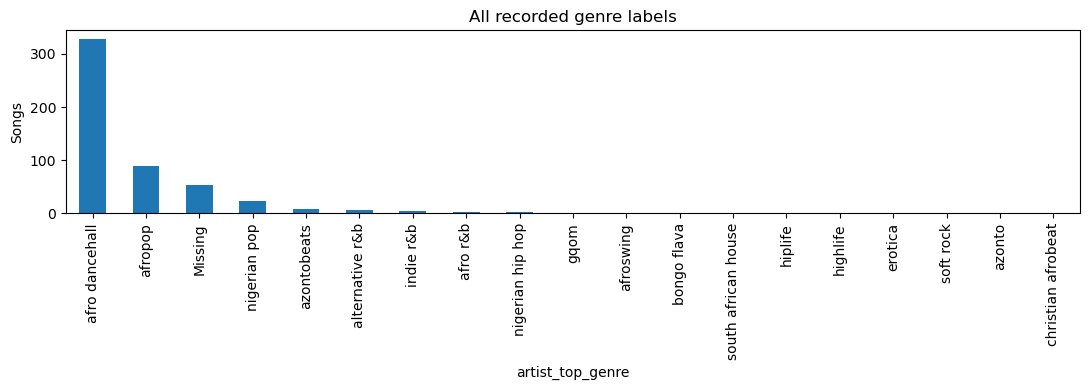

,popularity,danceability,energy,loudness,speechiness,tempo
popularity,1.000,0.070,-0.226,-0.108,-0.064,0.019
danceability,0.070,1.000,-0.072,-0.050,-0.204,-0.152
energy,-0.226,-0.072,1.000,0.724,-0.024,0.094
loudness,-0.108,-0.050,0.724,1.000,-0.046,0.093
speechiness,-0.064,-0.204,-0.024,-0.046,1.000,0.040
tempo,0.019,-0.152,0.094,0.093,0.040,1.000


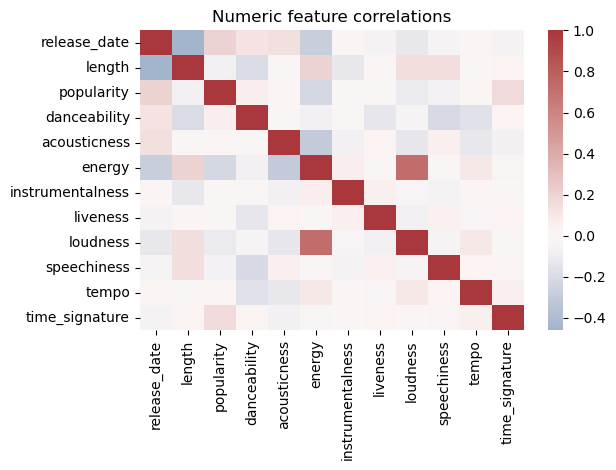

In [2]:
display(raw.head())
display(raw.describe())
raw.artist_top_genre.value_counts().plot.bar(figsize=(11, 4), title="All recorded genre labels")
plt.ylabel("Songs")
plt.tight_layout()
plt.show()
display(songs[["popularity", "danceability", "energy", "loudness", "speechiness", "tempo"]].corr().round(3))
sns.heatmap(songs.select_dtypes("number").corr(), cmap="vlag", center=0)
plt.title("Numeric feature correlations")
plt.tight_layout()
plt.show()

## Scatterplot 1 — Matplotlib with explicit genre groups

Popularity versus danceability recreates the lesson’s main comparison. Transparency makes overlaps visible. The same region contains several genre colors, so these two features alone do not visibly separate the genre labels. Each point is a song, not a listener preference.

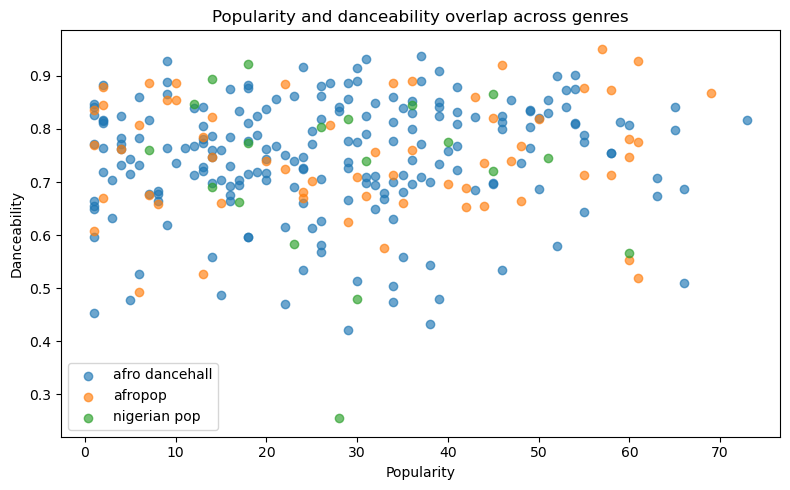

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for genre, group in songs.groupby("artist_top_genre"):
    ax.scatter(group.popularity, group.danceability, alpha=.65, label=genre)
ax.set(xlabel="Popularity", ylabel="Danceability", title="Popularity and danceability overlap across genres")
ax.legend()
fig.tight_layout()
plt.show()

## Scatterplot 2 — Seaborn semantic color and marker

Energy versus loudness shows whether two candidate clustering features are redundant. Genre is used for exploration only. An upward association means a clustering distance may count a related audio property twice if both columns receive equal weight.

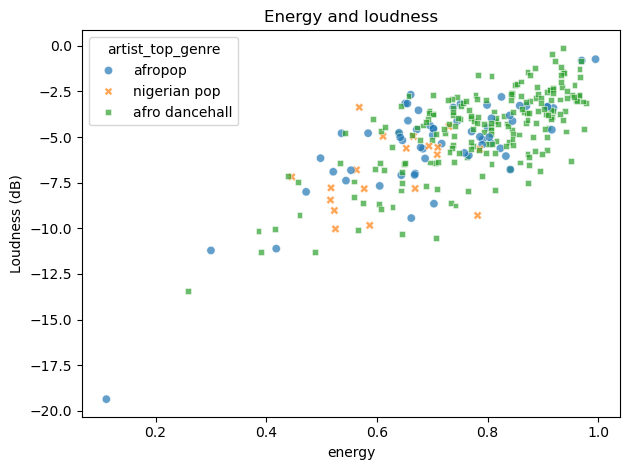

Energy/loudness correlation: 0.724


In [4]:
sns.scatterplot(data=songs, x="energy", y="loudness", hue="artist_top_genre", style="artist_top_genre", alpha=.7)
plt.title("Energy and loudness")
plt.ylabel("Loudness (dB)")
plt.tight_layout()
plt.show()
print("Energy/loudness correlation:", round(songs.energy.corr(songs.loudness), 3))

## Scatterplot 3 — pandas plotting with a continuous color scale

Tempo versus speechiness uses popularity as a continuous color rather than forcing it into categories. This helps inspect whether a relationship is consistent across popularity levels. A few high-speechiness songs need not form a stable cluster.

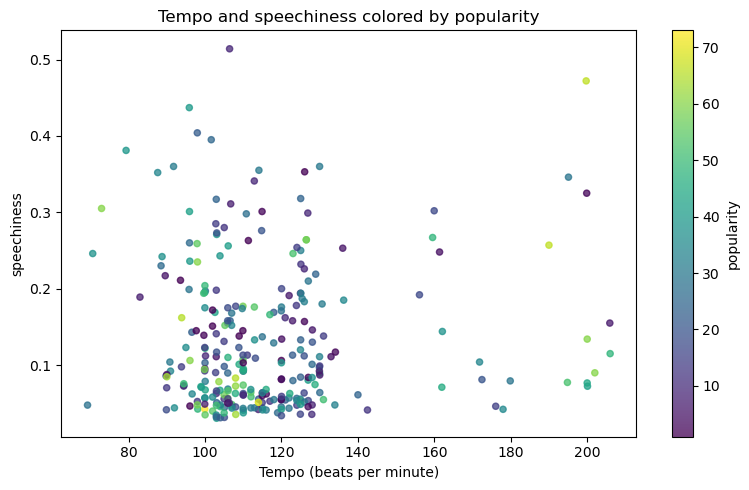

In [5]:
songs.plot.scatter(x="tempo", y="speechiness", c="popularity", colormap="viridis", alpha=.75, figsize=(8, 5), title="Tempo and speechiness colored by popularity")
plt.xlabel("Tempo (beats per minute)")
plt.tight_layout()
plt.show()

## Scatterplot 4 — Seaborn small multiples

Acousticness versus energy is split by genre with shared axes. This avoids one large genre visually hiding a smaller one. Sparse panels should not be interpreted with the same confidence as the larger panel.

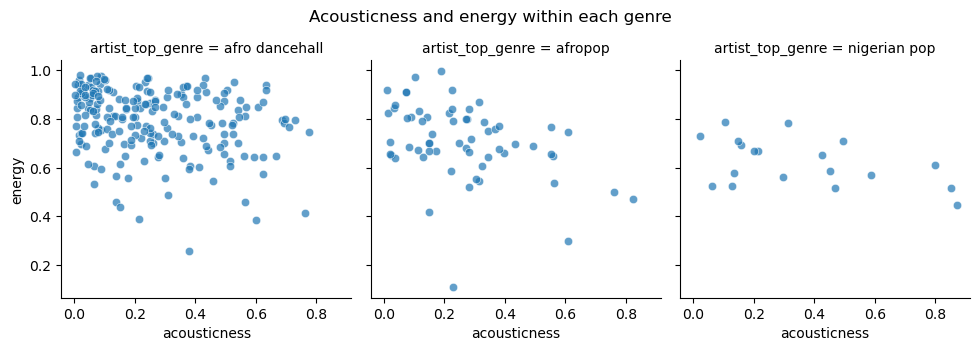

In [6]:
grid = sns.relplot(data=songs, x="acousticness", y="energy", col="artist_top_genre", col_order=genres, kind="scatter", alpha=.7, height=3.3)
grid.fig.suptitle("Acousticness and energy within each genre", y=1.05)
plt.show()

## Scatterplot 5 — Matplotlib size encoding

Track length versus danceability uses point area to represent energy. Length is converted from milliseconds to minutes for readable units. Size encoding adds context but overlapping large points can obscure observations; the first scatterplot is easier for precise comparisons.

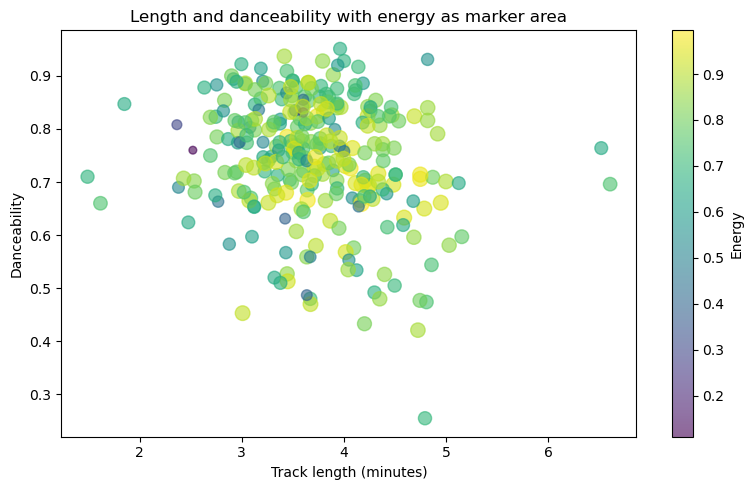

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(songs.length / 60000, songs.danceability, s=20 + 100 * songs.energy, c=songs.energy, cmap="viridis", alpha=.6)
ax.set(xlabel="Track length (minutes)", ylabel="Danceability", title="Length and danceability with energy as marker area")
fig.colorbar(points, ax=ax, label="Energy")
fig.tight_layout()
plt.show()
assert songs.length.gt(0).all()

## Lesson distribution exercise

The KDE smooths the observed points; contours are estimated density, not actual boundaries or proof of separate genres. Compare it with the raw scatterplot before proposing clusters.

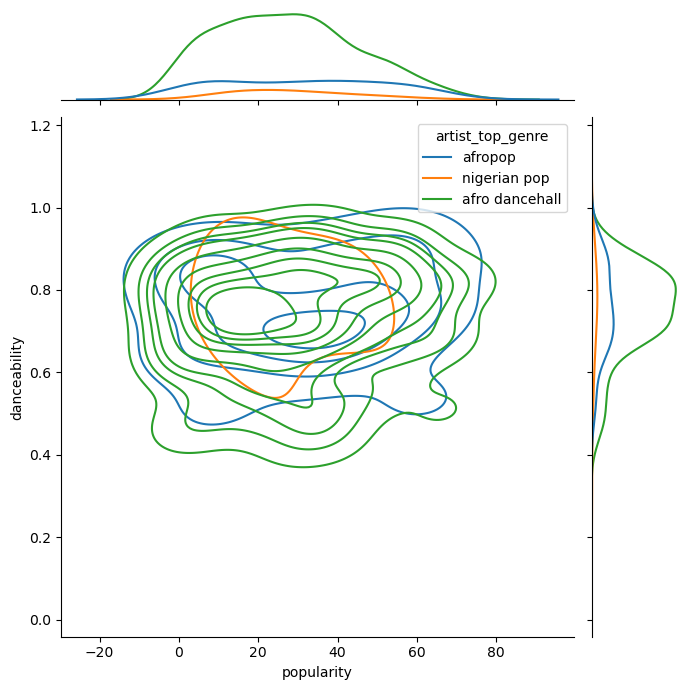

In [8]:
grid = sns.jointplot(data=songs, x="popularity", y="danceability", hue="artist_top_genre", kind="kde", height=7)
plt.show()

## Conclusions

These projections motivate scaling and checking correlated features before clustering. They do not show that music taste is determined by audio descriptors. The genre labels describe artists, which can differ from a song’s style. This filtered collection is not a random sample of Nigerian listeners or songs. See answers.md for the algorithm comparison chart and references to plotting APIs.